# Import Libraries

In [6]:
import pandas as pd
import numpy as np
import collections

# Import DataFrame

In [9]:
df_filepath = "merged_embeddings_sampled.pkl"

df = pd.read_pickle(df_filepath).reset_index(drop=True)

# EDA

Split dataset into train and test

In [13]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

le = LabelEncoder()

target_column = 'Party_orientation'
sentence_column = 'lemmas'
y = df[target_column]
X_lemmas = df[sentence_column]

TEST_SIZE = 0.1
RANDOM_STATE = 42

X_train_lemmas, X_test_lemmas, y_train, y_test = train_test_split(X_lemmas, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

Let us check whether we have class imbalance.

Party_orientation
Right    0.621028
Left     0.378972
Name: proportion, dtype: float64


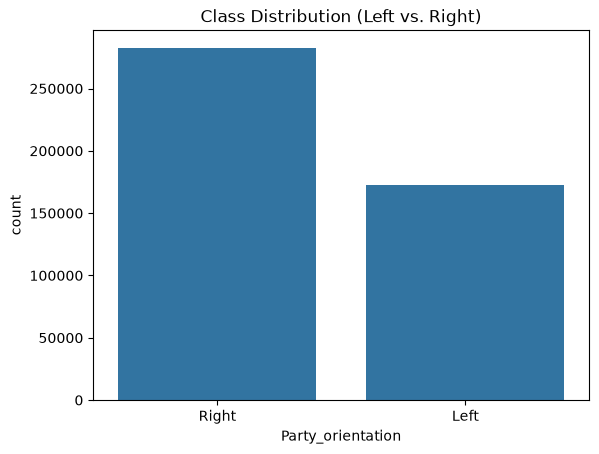

In [27]:
import seaborn as sns

g = sns.countplot(x=y_train) # Plotting class counts
g.set_title("Class Distribution (Left vs. Right)")

class_proportions = y_train.value_counts(normalize=True)
print(class_proportions) # Printing class probabilities

We can see we have a mild imbalance, with a skew towards the right.

For a 1D CNN, we need word-level representations. Therefore this implementation will focus on token indicators.

Since our CNN will take input at the word-level, we need to explicitly define a cutoff for the max length of the sentence. If input sentences are longer than this, they will be truncated to this max length. If shorter, it will be padded to this length using an explicit \<PAD> token.

Let's determine the max length empirically.

In [40]:
LENGTH_PERCENTILE = 0.95 # 95th percentile of sentence length
max_length = int(np.ceil(X_train_lemmas.apply(len).quantile(0.95)))

print(f"Max length: {max_length}")

Max length: 61


To conclude our EDA, we will use a 1D CNN with token indicators. We will use a max length of 61 and we will attempt to address the mild class imbalance.

Label Encoding Targets

In [42]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

Computing Class Weights

In [61]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights

array([1.31935847, 0.80511676])

Inspecting Index -> Class -> Weight Mapping

In [63]:
for idx, class_name in enumerate(le.classes_):
    print(f"Index {idx} -> {class_name} -> Weight: {class_weights[idx]:.4f}")

Index 0 -> Left -> Weight: 1.3194
Index 1 -> Right -> Weight: 0.8051


In this step we will transform our dataset of lemmas into a sequence of integers. Since we have way too many unique lemmas, we will derive our vocabulary size empirically as well.

We will make use of two extra tokens \<PAD> and \<UNK>:

1. The pad token will be used to ensure all our sentences have our empirically calculated max length. 

2. Our sequence encoder will take as input a frequency threshold. This determines the percentile of frequencies we would like our vocabulary to capture. We will group all lemmas not in our vocab into the unknown token.

In [65]:
class SequenceEncoder():
    def __init__(self, freq_threshold=0.8, max_length=50):
        self.freq_threshold = freq_threshold
        self.word_to_id = {}
        self.vocab = []
        self.vocab_size = 0
        self.pad_id = 0
        self.unk_id = None
        self.max_length = max_length

    def _calculate_threshold(self, token_frequencies):
        counts = np.array([count for _, count in token_frequencies.most_common()], dtype=np.uint64)
        cumulative_counts = np.cumsum(counts)
        normalized_cumulative_counts = cumulative_counts / cumulative_counts[-1]

        return int(np.searchsorted(normalized_cumulative_counts, self.freq_threshold) + 1)

    def fit(self, sentences):
        token_frequencies = collections.Counter()
        for sentence in sentences:
            token_frequencies.update(sentence)

        threshold = self._calculate_threshold(token_frequencies)
        top_lemmas_with_count = token_frequencies.most_common(threshold)

        self.vocab = [lemma for lemma, _ in top_lemmas_with_count]
        self.vocab_size = len(self.vocab) + 2 # 1 for <UNK> and 1 for <PAD>
        self.unk_id = self.vocab_size - 1

        self.word_to_id = {word: idx for idx, word in enumerate(self.vocab, start=1)}
        self.word_to_id['<PAD>'] = self.pad_id
        self.word_to_id['<UNK>'] = self.unk_id

        return self

    def transform(self, sentences):
        if not self.word_to_id:
            raise RuntimeError("SequenceEncoder must be fitted before calling transform().")

        num_samples = len(sentences)
        int_representations = np.zeros((num_samples, self.max_length), dtype=np.uint32)

        word_mapping = self.word_to_id
        unk_idx = self.unk_id
        max_len = self.max_length

        for i, sentence in enumerate(sentences):
            truncated = sentence[:max_len]
            for j, lemma in enumerate(truncated):
                int_representations[i, j] = word_mapping.get(lemma, unk_idx)

        return int_representations

    def fit_transform(self, sentences):
        return self.fit(sentences).transform(sentences)

In [66]:
encoder = SequenceEncoder(freq_threshold=0.8, max_length=max_length)
X_train_int = encoder.fit_transform(X_train_lemmas)
X_test_int = encoder.transform(X_test_lemmas)

print(f"Vocab size (including PAD & UNK): {encoder.vocab_size}")
print(f"X_train shape: {X_train_int.shape}")
print(f"X_test shape:  {X_test_int.shape}")

Vocab size (including PAD & UNK): 1128
X_train shape: (454833, 61)
X_test shape:  (50537, 61)


Let's now convert our dataset into tensors to work with PyTorch dataloaders.

In [71]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(X_train_int, dtype=torch.long)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_int, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_tensor_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_tensor_dataset = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 128
train_loader = DataLoader(train_tensor_dataset, batch_size, shuffle=True)
test_loader = DataLoader(test_tensor_dataset, batch_size, shuffle=False)

Defining Model Architecture (Using an Embeddings Layer)

In [95]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class EmbeddingConvNet(nn.Module):
    def __init__(self, vocab_size, num_classes=2, embedding_dim=256, output_channels=64, kernel_size=3, dropout=0.3, padding_idx=0):
        super(EmbeddingConvNet, self).__init__()
        self.emb = nn.Embedding(vocab_size, embedding_dim, padding_idx)
        self.conv1 = nn.Conv1d(embedding_dim, output_channels, kernel_size, padding='same')
        self.conv2 = nn.Conv1d(output_channels, output_channels, kernel_size, padding='same')
        self.conv3 = nn.Conv1d(output_channels, output_channels, kernel_size, padding='same')
        self.pool = nn.AdaptiveMaxPool1d(output_size=1)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(output_channels, num_classes)

    def forward(self, x):
        x = self.emb(x) # (batch, max_length) -> (batch, max_length, vocab_size)
        x = x.permute(0, 2, 1) # (batch, max_length, vocab_size) -> (batch, vocab_size, max_length)

        x = self.conv1(x)
        x = F.relu(x)

        x = self.conv2(x)
        x = F.relu(x)

        x = self.conv3(x)
        x = F.relu(x)

        x = self.pool(x)


        x = x.squeeze(-1) # (batch, output_channels, 1) -> (batch, output_channels)

        x = self.dropout(x)

        x = self.fc1(x)

        return x

In [96]:
import torch.optim as optim

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

model = EmbeddingConvNet(vocab_size=encoder.vocab_size).to(device)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights.astype(np.float32)).to(device))
optimizer = optim.Adam(model.parameters(), lr=0.001)

Training model

In [93]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import f1_score
from tqdm.auto import tqdm


def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, desc="Train", leave=False)

    for x, y in pbar:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        bs = y.size(0)
        total_loss += loss.item() * bs
        correct += (out.argmax(1) == y).sum().item()
        total += bs
        pbar.set_postfix(
            loss=f"{total_loss / total:.4f}", acc=f"{correct / total:.2%}"
        )

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    preds, targets = [], []
    pbar = tqdm(loader, desc="Val", leave=False)

    with torch.no_grad():
        for x, y in pbar:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)

            bs = y.size(0)
            pred = out.argmax(1)
            total_loss += loss.item() * bs
            correct += (pred == y).sum().item()
            total += bs

            preds.extend(pred.cpu().tolist())
            targets.extend(y.cpu().tolist())

    macro_f1 = f1_score(targets, preds, average="macro", zero_division=0)
    return total_loss / total, correct / total, macro_f1


def fit(
    model, train_loader, val_loader, criterion, optimizer, device, epochs=5
):
    history = []
    for epoch in range(1, epochs + 1):
        t_loss, t_acc = train_epoch(
            model, train_loader, criterion, optimizer, device
        )
        v_loss, v_acc, v_f1 = evaluate(model, val_loader, criterion, device)

        print(
            f"Epoch {epoch:02d}/{epochs:02d} | "
            f"Train Loss: {t_loss:.4f} - Acc: {t_acc:.2%} | "
            f"Val Loss: {v_loss:.4f} - Acc: {v_acc:.2%} - F1: {v_f1:.4f}"
        )

        history.append(
            {
                "epoch": epoch,
                "train_loss": t_loss,
                "val_loss": v_loss,
                "train_acc": t_acc,
                "val_acc": v_acc,
                "val_macro_f1": v_f1,
            }
        )

    return pd.DataFrame(history)


def plot_metrics(df):
    sns.set_theme(style="whitegrid")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    # Loss Curves
    sns.lineplot(
        data=df,
        x="epoch",
        y="train_loss",
        label="Train Loss",
        marker="o",
        ax=ax1,
    )
    sns.lineplot(
        data=df, x="epoch", y="val_loss", label="Val Loss", marker="o", ax=ax1
    )
    ax1.set_title("Cross-Entropy Loss", fontweight="bold")
    ax1.set_ylabel("Loss")

    # Metric Curves
    sns.lineplot(
        data=df,
        x="epoch",
        y="val_macro_f1",
        label="Val Macro F1",
        marker="o",
        ax=ax2,
    )
    sns.lineplot(
        data=df,
        x="epoch",
        y="val_acc",
        label="Val Accuracy",
        marker="s",
        ax=ax2,
    )
    ax2.set_title("Validation Macro F1 & Accuracy", fontweight="bold")
    ax2.set_ylabel("Score")
    ax2.set_ylim(0, 1.0)

    plt.tight_layout()
    plt.show()

Epoch 01/05 | Train Loss: 0.5526 - Acc: 69.96% | Val Loss: 0.6278 - Acc: 66.00% - F1: 0.6506


Epoch 02/05 | Train Loss: 0.5443 - Acc: 70.51% | Val Loss: 0.6259 - Acc: 65.11% - F1: 0.6443


Epoch 03/05 | Train Loss: 0.5368 - Acc: 71.12% | Val Loss: 0.6358 - Acc: 65.15% - F1: 0.6449


Epoch 04/05 | Train Loss: 0.5285 - Acc: 71.63% | Val Loss: 0.6409 - Acc: 64.53% - F1: 0.6402


Epoch 05/05 | Train Loss: 0.5211 - Acc: 71.99% | Val Loss: 0.6637 - Acc: 65.03% - F1: 0.6430


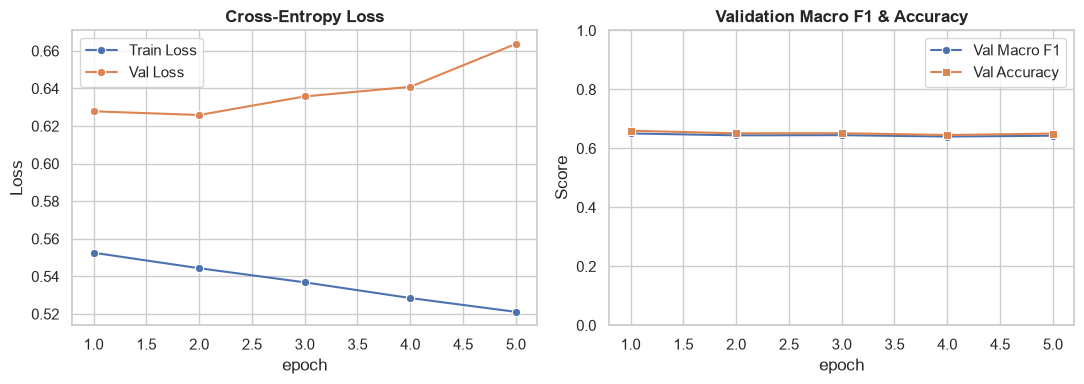

In [94]:
history_df = fit(
    model, train_loader, test_loader, criterion, optimizer, device, epochs=5
)
plot_metrics(history_df)

Hyperparameter Search with Optuna

In [97]:
import optuna


def objective(
    trial,
    vocab_size,
    train_loader,
    val_loader,
    criterion,
    device,
    epochs_per_trial=4,
):
    # 1. Hyperparameter search space
    embedding_dim = trial.suggest_categorical(
        "embedding_dim", [64, 128, 256]
    )
    output_channels = trial.suggest_categorical(
        "output_channels", [32, 64, 128]
    )
    kernel_size = trial.suggest_categorical("kernel_size", [3, 5])
    dropout = trial.suggest_float("dropout", 0.1, 0.5, step=0.1)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)

    # 2. Instantiate model and optimizer
    model = EmbeddingConvNet(
        vocab_size=vocab_size,
        num_classes=2,
        embedding_dim=embedding_dim,
        output_channels=output_channels,
        kernel_size=kernel_size,
        dropout=dropout,
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )

    best_val_f1 = 0.0

    # 3. Training & Evaluation loop per trial
    for epoch in range(1, epochs_per_trial + 1):
        train_epoch(model, train_loader, criterion, optimizer, device)
        _, _, val_macro_f1 = evaluate(model, val_loader, criterion, device)

        # Track best score in trial
        if val_macro_f1 > best_val_f1:
            best_val_f1 = val_macro_f1

        # Optuna pruning: report intermediate metric and prune if unpromising
        trial.report(val_macro_f1, step=epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return best_val_f1

In [104]:
# Create study with MedianPruner to kill bad trials after epoch 2
pruner = optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=2)
study = optuna.create_study(direction="maximize", pruner=pruner)

# Execute 15-20 trials (fast enough for tonight's deadline)
study.optimize(
    lambda trial: objective(
        trial,
        vocab_size=encoder.vocab_size,
        train_loader=train_loader,
        val_loader=test_loader,
        criterion=criterion,
        device=device,
        epochs_per_trial=4,
    ),
    n_trials=15,
)

# Best results
print(f"Best Validation Macro F1: {study.best_value:.4f}")
print("Best Hyperparameters:")
for param, val in study.best_params.items():
    print(f"  {param}: {val}")

[I 2026-11-08 12:24:34,323] A new study created in memory with name: no-name-febf7a03-9a1a-4762-a54a-d4870aca7bfa
[I 2026-11-08 12:27:08,247] Trial 0 finished with value: 0.6382334939549348 and parameters: {'embedding_dim': 64, 'output_channels': 32, 'kernel_size': 3, 'dropout': 0.4, 'lr': 0.0008236356954013726, 'weight_decay': 0.0002057378759800489}. Best is trial 0 with value: 0.6382334939549348.
[I 2026-11-08 12:30:56,758] Trial 1 finished with value: 0.6468708380026471 and parameters: {'embedding_dim': 64, 'output_channels': 128, 'kernel_size': 3, 'dropout': 0.1, 'lr': 0.00019571517010501688, 'weight_decay': 1.530726791539962e-05}. Best is trial 1 with value: 0.6468708380026471.
[I 2026-11-08 12:34:03,996] Trial 2 finished with value: 0.6259420288716401 and parameters: {'embedding_dim': 256, 'output_channels': 32, 'kernel_size': 3, 'dropout': 0.5, 'lr': 0.0032358431011896495, 'weight_decay': 0.0004971819284457146}. Best is trial 1 with value: 0.6468708380026471.
[I 2026-11-08 12:36

Best Validation Macro F1: 0.6469
Best Hyperparameters:
  embedding_dim: 64
  output_channels: 128
  kernel_size: 3
  dropout: 0.1
  lr: 0.00019571517010501688
  weight_decay: 1.530726791539962e-05


# Running Cross-Validation

In [ ]:
# ---------------------------------------------------------
# 1. SETUP: REPLICATE FOLDS ON CURRENT DATASET
# ---------------------------------------------------------
import random
import numpy as np
import pandas as pd
from pathlib import Path
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

import part1

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

# Load YOUR preprocessed dataset
df_matched = pd.read_pickle("merged_embeddings_sampled.pkl")

# Apply exact shuffling and train/test split from other notebook to guarantee matching rows
df_matched = df_matched.sample(frac=1.0, random_state=42).reset_index(drop=True)

LABEL_COL = "Party_orientation"
train_df_c, test_df_c = train_test_split(
    df_matched, 
    test_size=0.1, 
    random_state=42, 
    stratify=df_matched[LABEL_COL]
)
train_df_c = train_df_c.reset_index(drop=True)

label_names = sorted(df_matched[LABEL_COL].unique())
my_seeds = [0, 1, 2]
num_folds = 5

def make_pairs(df, column, label_names, label_column=LABEL_COL):
    label_to_id = {name: i for i, name in enumerate(label_names)}
    texts = df[column]
    if isinstance(texts.iloc[0], (list, tuple, np.ndarray)):
        texts = texts.str.join(" ")
    labels = [label_to_id[name] for name in df[label_column]]
    return list(zip(texts, labels))

# Generate the EXACT same fold partitions as other notebook using part1
pairs = make_pairs(train_df_c, "lemmas", label_names)
cv_lemmas = [part1.experiment.cross_validation_split(pairs=pairs, k=num_folds, seed=seed) for seed in my_seeds]
test_pairs = make_pairs(test_df_c, "lemmas", label_names)

# Convert string pairs to PyTorch DataLoaders using your sequence encoder
def pairs_to_dataloader(pairs_list, encoder, batch_size, shuffle=False):
    texts = [text.split() for text, _ in pairs_list] 
    labels = [label for _, label in pairs_list]
    
    X_int = encoder.transform(texts)
    X_tensor = torch.tensor(X_int, dtype=torch.long)
    y_tensor = torch.tensor(labels, dtype=torch.long)
    
    dataset = TensorDataset(X_tensor, y_tensor)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

test_loader_global = pairs_to_dataloader(test_pairs, encoder, batch_size=128, shuffle=False)
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

In [ ]:
# ---------------------------------------------------------
# 2. RUN EMBEDDING CNN ON CROSS-VALIDATION FOLDS
# ---------------------------------------------------------
from sklearn.metrics import accuracy_score, f1_score
import torch.optim as optim

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

# Frozen Best Parameters from Optuna (Embeddings)
best_params_emb = {
    'embedding_dim': 64,
    'output_channels': 128,
    'kernel_size': 3,
    'dropout': 0.1,
    'lr': 0.0001957,
    'weight_decay': 1.53e-05,
    'epochs': 5
}

def run_cv_experiment(experiment_name, ModelClass, model_kwargs, params, use_one_hot=False):
    (results_folder / experiment_name).mkdir(exist_ok=True)
    cv_rows, test_rows = [], []
    
    for run_idx, seed in enumerate(my_seeds):
        splits = cv_lemmas[run_idx]
        for fold in splits:
            set_seed(seed)
            train_loader = pairs_to_dataloader(splits[fold]["training"], encoder, batch_size=128, shuffle=True)
            val_loader = pairs_to_dataloader(splits[fold]["validation"], encoder, batch_size=128, shuffle=False)
            
            model = ModelClass(**model_kwargs).to(device)
            criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights.astype(np.float32)).to(device))
            optimizer = optim.Adam(model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
            
            # Train
            for epoch in range(params['epochs']):
                model.train()
                for x, y in train_loader:
                    if use_one_hot:
                        x = F.one_hot(x, num_classes=encoder.vocab_size).float()
                    x, y = x.to(device), y.to(device)
                    optimizer.zero_grad()
                    loss = criterion(model(x), y)
                    loss.backward()
                    optimizer.step()
                    
            # Evaluate Validation Fold (CV Score)
            model.eval()
            val_preds, val_targets = [], []
            with torch.no_grad():
                for x, y in val_loader:
                    if use_one_hot:
                        x = F.one_hot(x, num_classes=encoder.vocab_size).float()
                    x = x.to(device)
                    val_preds.extend(model(x).argmax(1).cpu().tolist())
                    val_targets.extend(y.tolist())
                    
            cv_rows.append({
                "seed": seed, "fold": fold, 
                "accuracy": accuracy_score(val_targets, val_preds), 
                "f1": f1_score(val_targets, val_preds, average="macro")
            })
            
            # Evaluate Test Set (Test Score)
            test_preds, test_targets = [], []
            with torch.no_grad():
                for x, y in test_loader_global:
                    if use_one_hot:
                        x = F.one_hot(x, num_classes=encoder.vocab_size).float()
                    x = x.to(device)
                    test_preds.extend(model(x).argmax(1).cpu().tolist())
                    test_targets.extend(y.tolist())
                    
            test_rows.append({
                "seed": seed, "fold": fold, 
                "accuracy": accuracy_score(test_targets, test_preds), 
                "f1": f1_score(test_targets, test_preds, average="macro")
            })
            print(f"{experiment_name} | Seed {seed} Fold {fold} Done.")
            
    # Save to match formats
    pd.DataFrame(cv_rows).to_csv(results_folder / experiment_name / "cv_scores.csv", index=False)
    pd.DataFrame(test_rows).to_csv(results_folder / experiment_name / "test_scores.csv", index=False)

# Run Embedding CNN Task
emb_kwargs = {
    'vocab_size': encoder.vocab_size, 'num_classes': 2,
    'embedding_dim': best_params_emb['embedding_dim'],
    'output_channels': best_params_emb['output_channels'],
    'kernel_size': best_params_emb['kernel_size'],
    'dropout': best_params_emb['dropout']
}
run_cv_experiment("cnn_embeddings", EmbeddingConvNet, emb_kwargs, best_params_emb, use_one_hot=False)

cnn_embeddings | Seed 0 Fold 0 Done.
cnn_embeddings | Seed 0 Fold 1 Done.
cnn_embeddings | Seed 0 Fold 2 Done.
cnn_embeddings | Seed 0 Fold 3 Done.
cnn_embeddings | Seed 0 Fold 4 Done.
cnn_embeddings | Seed 1 Fold 0 Done.
cnn_embeddings | Seed 1 Fold 1 Done.
cnn_embeddings | Seed 1 Fold 2 Done.
cnn_embeddings | Seed 1 Fold 3 Done.
cnn_embeddings | Seed 1 Fold 4 Done.
cnn_embeddings | Seed 2 Fold 0 Done.
cnn_embeddings | Seed 2 Fold 1 Done.
cnn_embeddings | Seed 2 Fold 2 Done.
cnn_embeddings | Seed 2 Fold 3 Done.
cnn_embeddings | Seed 2 Fold 4 Done.


# Experimenting with Token Indicators instead of Embedding Layer

In [111]:
# ---------------------------------------------------------
# 3. DEFINE ONE-HOT 1D CNN MODEL 
# ---------------------------------------------------------
class OneHotConvNet(nn.Module):
    def __init__(self, vocab_size, num_classes=2, output_channels=64, kernel_size=3, dropout=0.3):
        super(OneHotConvNet, self).__init__()
        # Input channels = vocab_size because one-hot creates feature dimension of vocab_size
        self.conv1 = nn.Conv1d(vocab_size, output_channels, kernel_size, padding='same')
        self.conv2 = nn.Conv1d(output_channels, output_channels, kernel_size, padding='same')
        self.conv3 = nn.Conv1d(output_channels, output_channels, kernel_size, padding='same')
        self.pool = nn.AdaptiveMaxPool1d(output_size=1)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(output_channels, num_classes)

    def forward(self, x):
        # x input shape from DataLoader with F.one_hot: (batch, max_length, vocab_size)
        x = x.permute(0, 2, 1) # -> (batch, vocab_size, max_length)

        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = self.pool(x).squeeze(-1) # (batch, channels, 1) -> (batch, channels)
        x = self.dropout(x)
        return self.fc1(x)

In [112]:
# ---------------------------------------------------------
# 4. OPTUNA HYPERPARAMETER SEARCH FOR ONE-HOT CNN
# ---------------------------------------------------------
import optuna

def objective_onehot(trial):
    output_channels = trial.suggest_categorical("output_channels", [32, 64, 128])
    kernel_size = trial.suggest_categorical("kernel_size", [3, 5])
    dropout = trial.suggest_float("dropout", 0.1, 0.5, step=0.1)
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)

    model = OneHotConvNet(
        vocab_size=encoder.vocab_size,
        num_classes=2,
        output_channels=output_channels,
        kernel_size=kernel_size,
        dropout=dropout,
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights.astype(np.float32)).to(device))

    best_val_f1 = 0.0
    for epoch in range(1, 5): # 4 epochs per trial
        model.train()
        for x, y in train_loader: # using original train_loader from notebook state
            x = F.one_hot(x, num_classes=encoder.vocab_size).float().to(device)
            y = y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        model.eval()
        val_preds, val_targets = [], []
        with torch.no_grad():
            for x, y in test_loader: # using original test_loader as val
                x = F.one_hot(x, num_classes=encoder.vocab_size).float().to(device)
                val_preds.extend(model(x).argmax(1).cpu().tolist())
                val_targets.extend(y.tolist())
                
        val_macro_f1 = f1_score(val_targets, val_preds, average="macro", zero_division=0)
        if val_macro_f1 > best_val_f1:
            best_val_f1 = val_macro_f1

        trial.report(val_macro_f1, step=epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return best_val_f1

pruner = optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=2)
study_onehot = optuna.create_study(direction="maximize", pruner=pruner)
study_onehot.optimize(objective_onehot, n_trials=15)

print(f"Best Validation Macro F1: {study_onehot.best_value:.4f}")
print("Best Hyperparameters:", study_onehot.best_params)

[I 2026-11-08 14:25:37,886] A new study created in memory with name: no-name-47f44030-39b5-4441-8127-68f78e7ec558
[I 2026-11-08 14:32:54,828] Trial 0 finished with value: 0.6376474743671402 and parameters: {'output_channels': 64, 'kernel_size': 5, 'dropout': 0.1, 'lr': 0.003918866113767756, 'weight_decay': 0.00020337857814059447}. Best is trial 0 with value: 0.6376474743671402.
[I 2026-11-08 14:39:52,503] Trial 1 finished with value: 0.6298897237646746 and parameters: {'output_channels': 32, 'kernel_size': 5, 'dropout': 0.30000000000000004, 'lr': 0.0001514114914855642, 'weight_decay': 3.3854343612886765e-05}. Best is trial 0 with value: 0.6376474743671402.
[I 2026-11-08 14:46:48,154] Trial 2 finished with value: 0.6433138382772872 and parameters: {'output_channels': 32, 'kernel_size': 5, 'dropout': 0.5, 'lr': 0.000435197258264573, 'weight_decay': 1.971621225431644e-05}. Best is trial 2 with value: 0.6433138382772872.
[I 2026-11-08 14:50:14,735] Trial 3 pruned. 
[I 2026-11-08 14:53:43,1

Best Validation Macro F1: 0.6555
Best Hyperparameters: {'output_channels': 64, 'kernel_size': 3, 'dropout': 0.30000000000000004, 'lr': 0.0007157302750685319, 'weight_decay': 4.542549894142034e-05}


In [113]:
# ---------------------------------------------------------
# 5. RUN ONE-HOT CNN ON CROSS-VALIDATION FOLDS
# ---------------------------------------------------------

# Freeze best hyperparameters dynamically from study
best_params_onehot = study_onehot.best_params
best_params_onehot['epochs'] = 5 # Standardize epochs

onehot_kwargs = {
    'vocab_size': encoder.vocab_size,
    'num_classes': 2,
    'output_channels': best_params_onehot['output_channels'],
    'kernel_size': best_params_onehot['kernel_size'],
    'dropout': best_params_onehot['dropout']
}

run_cv_experiment("cnn_onehot", OneHotConvNet, onehot_kwargs, best_params_onehot, use_one_hot=True)

cnn_onehot | Seed 0 Fold 0 Done.
cnn_onehot | Seed 0 Fold 1 Done.
cnn_onehot | Seed 0 Fold 2 Done.
cnn_onehot | Seed 0 Fold 3 Done.
cnn_onehot | Seed 0 Fold 4 Done.
cnn_onehot | Seed 1 Fold 0 Done.
cnn_onehot | Seed 1 Fold 1 Done.
cnn_onehot | Seed 1 Fold 2 Done.
cnn_onehot | Seed 1 Fold 3 Done.
cnn_onehot | Seed 1 Fold 4 Done.
cnn_onehot | Seed 2 Fold 0 Done.
cnn_onehot | Seed 2 Fold 1 Done.
cnn_onehot | Seed 2 Fold 2 Done.
cnn_onehot | Seed 2 Fold 3 Done.
cnn_onehot | Seed 2 Fold 4 Done.


In [ ]:
# ---------------------------------------------------------
# 6. RESULTS COMPARISON
# ---------------------------------------------------------
def load_scores(kind="cv"):
    """All saved scores of one kind ("cv" or "test"), one row per (model, seed, fold)."""
    frames = [pd.read_csv(path).assign(model=path.parent.name) for path in sorted(results_folder.glob(f"*/{kind}_scores.csv"))]
    return pd.concat(frames, ignore_index=True)[["model", "seed", "fold", "accuracy", "f1"]]

summary = pd.concat({
    "cv": load_scores("cv").groupby("model")[["accuracy", "f1"]].agg(["mean", "std"]),
    "test": load_scores("test").groupby("model")[["accuracy", "f1"]].agg(["mean", "std"]),
}, axis=1)

majority = test_df_c[LABEL_COL].value_counts(normalize=True).max()
print(f"majority-class baseline: accuracy {majority:.4f}, macro F1 {majority / (1 + majority):.4f}")
display(summary.round(4))

majority-class baseline: accuracy 0.6210, macro F1 0.3831


cv                             test          \
                          accuracy              f1         accuracy           
                              mean     std    mean     std     mean     std   
model                                                                         
cnn_embeddings              0.6528  0.0116  0.6433  0.0050   0.6534  0.0106   
cnn_onehot                  0.6485  0.0108  0.6417  0.0066   0.6490  0.0106   
logistic_bow-lemmas         0.6851  0.0030  0.6323  0.0065   0.6845  0.0024   
logistic_embeddings         0.6569  0.0018  0.5930  0.0019   0.6559  0.0005   
logistic_indicator-lemmas   0.6903  0.0015  0.6466  0.0015   0.6890  0.0007   
mlp_bow-lemmas              0.7021  0.0015  0.6649  0.0050   0.7005  0.0010   
mlp_embeddings              0.6891  0.0019  0.6538  0.0040   0.6879  0.0012   
mlp_indicator-lemmas        0.7032  0.0021  0.6678  0.0037   0.7008  0.0014   

                                           
                               f1          
                             mean     std  
model                                      
cnn_embeddings             0.6436  0.0042  
cnn_onehot                 0.6419  0.0060  
logistic_bow-lemmas        0.6309  0.0059  
logistic_embeddings        0.5911  0.0005  
logistic_indicator-lemmas  0.6443  0.0009  
mlp_bow-lemmas             0.6627  0.0048  
mlp_embeddings             0.6521  0.0035  
mlp_indicator-lemmas       0.6648  0.0036

# Making graphs

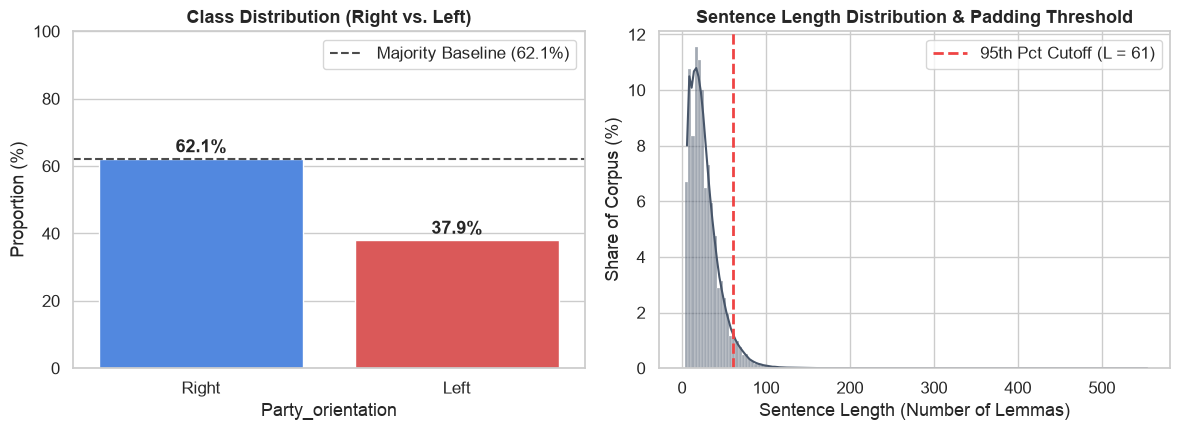

In [115]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot A: Class Imbalance
class_counts = df["Party_orientation"].value_counts(normalize=True) * 100
palette = {"Right": "#3b82f6", "Left": "#ef4444"}
bars = sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    ax=ax1,
    palette=palette,
    hue=class_counts.index,
    legend=False,
)
ax1.axhline(62.1, color="black", linestyle="--", alpha=0.7, label="Majority Baseline (62.1%)")
ax1.set_ylabel("Proportion (%)")
ax1.set_title("Class Distribution (Right vs. Left)", fontweight="bold")
ax1.set_ylim(0, 100)
for p in bars.patches:
  ax1.annotate(
      f"{p.get_height():.1f}%",
      (p.get_x() + p.get_width() / 2.0, p.get_height() + 2),
      ha="center",
      fontweight="bold",
  )
ax1.legend(loc="upper right")

# Plot B: Sentence Length Distribution (95th Percentile)
lengths = df["lemmas"].apply(len)
sns.histplot(
    lengths,
    bins=40,
    kde=True,
    color="#475569",
    ax=ax2,
    stat="percent",
    binrange=(0, 150),
)
ax2.axvline(
    61,
    color="#ef4444",
    linestyle="--",
    linewidth=2,
    label="95th Pct Cutoff (L = 61)",
)
ax2.set_xlabel("Sentence Length (Number of Lemmas)")
ax2.set_ylabel("Share of Corpus (%)")
ax2.set_title("Sentence Length Distribution & Padding Threshold", fontweight="bold")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

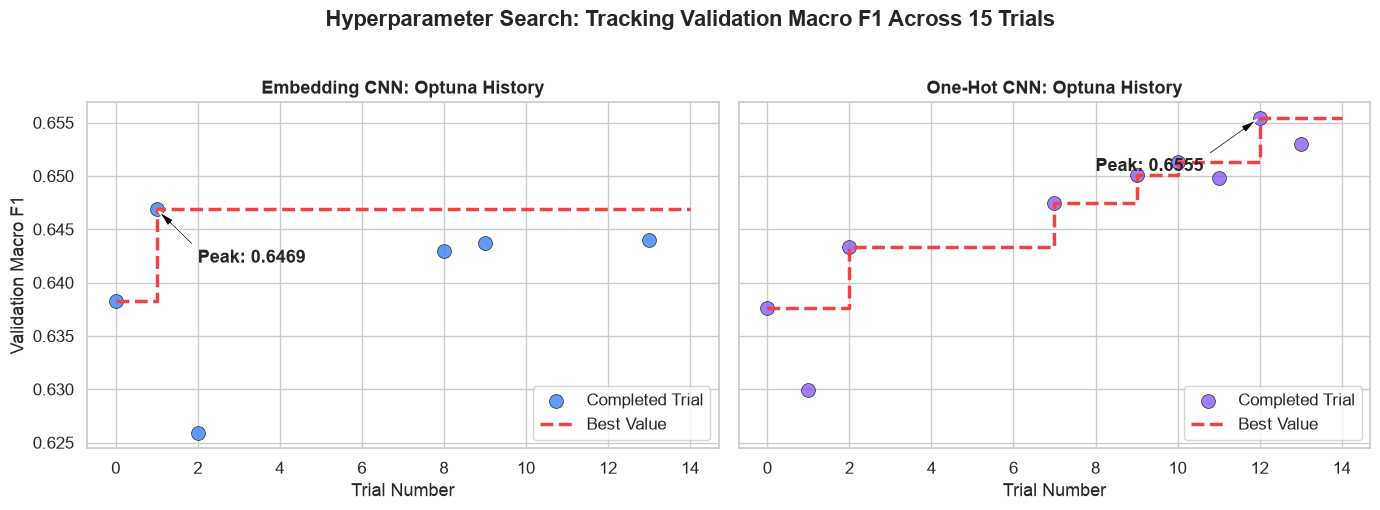

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------
# 1. LOAD ACTUAL OPTUNA LOG DATA
# ---------------------------------------------------------

# Embedding CNN Data (15 Trials)
trials = np.arange(15)
emb_f1 = [
    0.638233, 0.646870, 0.625942, np.nan, np.nan, np.nan, np.nan, np.nan, 
    0.643005, 0.643676, np.nan, np.nan, np.nan, 0.643970, np.nan
]

# One-Hot CNN Data (15 Trials)
onehot_f1 = [
    0.637647, 0.629889, 0.643313, np.nan, np.nan, np.nan, np.nan, 0.647441, 
    np.nan, 0.650108, 0.651347, 0.649810, 0.655466, 0.652971, np.nan
]

def calculate_best_history(f1_scores):
    """Calculates the cumulative best score up to each trial."""
    best_history = []
    current_best = np.nan
    for score in f1_scores:
        if not np.isnan(score):
            if np.isnan(current_best) or score > current_best:
                current_best = score
        best_history.append(current_best)
    return best_history

emb_best = calculate_best_history(emb_f1)
onehot_best = calculate_best_history(onehot_f1)

# Combine into DataFrames for Seaborn
df_emb = pd.DataFrame({"Trial": trials, "Macro F1": emb_f1, "Best F1": emb_best, "Model": "Embedding CNN"})
df_onehot = pd.DataFrame({"Trial": trials, "Macro F1": onehot_f1, "Best F1": onehot_best, "Model": "One-Hot CNN"})

# ---------------------------------------------------------
# 2. PLOT THE OPTIMIZATION HISTORY
# ---------------------------------------------------------

sns.set_theme(style="whitegrid", font_scale=1.1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Define aesthetics
scatter_kws = {"s": 100, "alpha": 0.8, "edgecolor": "black", "linewidth": 0.5}
line_kws = {"linewidth": 2.5, "linestyle": "--", "drawstyle": "steps-post"}

# --- Plot A: Embedding CNN ---
sns.scatterplot(data=df_emb, x="Trial", y="Macro F1", color="#3b82f6", label="Completed Trial", ax=ax1, **scatter_kws)
ax1.plot(df_emb["Trial"], df_emb["Best F1"], color="#ef4444", label="Best Value", **line_kws)
ax1.set_title("Embedding CNN: Optuna History", fontweight="bold")
ax1.set_xlabel("Trial Number")
ax1.set_ylabel("Validation Macro F1")
ax1.set_xticks(range(0, 16, 2))
ax1.legend(loc="lower right")

# Annotate Best Embedding Score
best_emb_idx = 1
ax1.annotate(
    f"Peak: {emb_f1[best_emb_idx]:.4f}", 
    xy=(best_emb_idx, emb_f1[best_emb_idx]), 
    xytext=(best_emb_idx + 1, emb_f1[best_emb_idx] - 0.005),
    arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
    fontweight="bold"
)

# --- Plot B: One-Hot CNN ---
sns.scatterplot(data=df_onehot, x="Trial", y="Macro F1", color="#8b5cf6", label="Completed Trial", ax=ax2, **scatter_kws)
ax2.plot(df_onehot["Trial"], df_onehot["Best F1"], color="#ef4444", label="Best Value", **line_kws)
ax2.set_title("One-Hot CNN: Optuna History", fontweight="bold")
ax2.set_xlabel("Trial Number")
ax2.set_xticks(range(0, 16, 2))
ax2.legend(loc="lower right")

# Annotate Best One-Hot Score
best_oh_idx = 12
ax2.annotate(
    f"Peak: {onehot_f1[best_oh_idx]:.4f}", 
    xy=(best_oh_idx, onehot_f1[best_oh_idx]), 
    xytext=(best_oh_idx - 4, onehot_f1[best_oh_idx] - 0.005),
    arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
    fontweight="bold"
)

plt.suptitle("Hyperparameter Search: Tracking Validation Macro F1 Across 15 Trials", fontweight="bold", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [122]:
# ---------------------------------------------------------
# 6. FINAL RESULTS COMPARISON (Including CNNs)
# ---------------------------------------------------------
import pandas as pd
from IPython.display import display

def load_scores(kind="cv"):
    """Loads all saved scores of one kind ("cv" or "test"), one row per (model, seed, fold)."""
    # This automatically grabs Chris's models + your new cnn_embeddings & cnn_onehot
    frames = [pd.read_csv(path).assign(model=path.parent.name) for path in sorted(results_folder.glob(f"*/{kind}_scores.csv"))]
    if not frames:
        raise ValueError(f"No {kind} CSVs found in {results_folder}. Check your folder paths.")
    return pd.concat(frames, ignore_index=True)[["model", "seed", "fold", "accuracy", "f1"]]

# Aggregate mean and standard deviation for both CV and Test scores
summary = pd.concat({
    "cv": load_scores("cv").groupby("model")[["accuracy", "f1"]].agg(["mean", "std"]),
    "test": load_scores("test").groupby("model")[["accuracy", "f1"]].agg(["mean", "std"]),
}, axis=1)

# Calculate majority-class baseline using your matched dataset
majority = test_df_c[LABEL_COL].value_counts(normalize=True).max()

print("=== BASELINES ===")
print(f"Majority-Class Baseline: Accuracy = {majority:.4f} | Macro F1 = {majority / (1 + majority):.4f}\n")

print("=== FINAL MODEL COMPARISON (MEAN ± STD) ===")
display(summary.round(4))

=== BASELINES ===
Majority-Class Baseline: Accuracy = 0.6210 | Macro F1 = 0.3831

=== FINAL MODEL COMPARISON (MEAN ± STD) ===


cv                             test          \
                          accuracy              f1         accuracy           
                              mean     std    mean     std     mean     std   
model                                                                         
cnn_embeddings              0.6528  0.0116  0.6433  0.0050   0.6534  0.0106   
cnn_onehot                  0.6485  0.0108  0.6417  0.0066   0.6490  0.0106   
logistic_bow-lemmas         0.6851  0.0030  0.6323  0.0065   0.6845  0.0024   
logistic_embeddings         0.6569  0.0018  0.5930  0.0019   0.6559  0.0005   
logistic_indicator-lemmas   0.6903  0.0015  0.6466  0.0015   0.6890  0.0007   
mlp_bow-lemmas              0.7021  0.0015  0.6649  0.0050   0.7005  0.0010   
mlp_embeddings              0.6891  0.0019  0.6538  0.0040   0.6879  0.0012   
mlp_indicator-lemmas        0.7032  0.0021  0.6678  0.0037   0.7008  0.0014   

                                           
                               f1          
                             mean     std  
model                                      
cnn_embeddings             0.6436  0.0042  
cnn_onehot                 0.6419  0.0060  
logistic_bow-lemmas        0.6309  0.0059  
logistic_embeddings        0.5911  0.0005  
logistic_indicator-lemmas  0.6443  0.0009  
mlp_bow-lemmas             0.6627  0.0048  
mlp_embeddings             0.6521  0.0035  
mlp_indicator-lemmas       0.6648  0.0036